# WMC Practical Examination — Statement #07
## Smart Home Security & Automation System using Cisco Packet Tracer (IoT)

**Problem statement.** Design and simulate a smart home security and automation system in Cisco Packet Tracer. Configure the system to control the following devices based on movement detected in two different rooms:

1. **Motion Detector 1 (Room A):** When Motion Detector 1 detects movement in Room A, the Smart Light and Siren must switch ON.
2. **Motion Detector 2 (Room B):** When Motion Detector 2 detects movement in Room B, the Appliance and Webcam must switch ON.
3. **No-Motion Condition:** When Motion Detector 1 does not detect movement, the Smart Light must switch OFF.

---
**Aim:** To design an IoT-based smart home in Cisco Packet Tracer in which two motion detectors (Room A and Room B), connected wirelessly to a Home Gateway, control a Smart Light, Smart Fan, Siren, Appliance and Webcam through rule-based IoT conditions — including a **no-motion (not) condition**.

**Software / components:** Cisco Packet Tracer 8.x · Home Gateway (DLC100) · 2 × Motion Detector · Light (Smart Light) · Ceiling Fan (Smart Fan) · Siren · Appliance · Webcam · Smartphone (or Laptop) for the IoT web interface.

> **About this notebook.** Packet Tracer itself is a GUI tool, so Part A below is the exact build procedure for the `.pkt` file. Part B is an executed Python model of the *same* Home Gateway rule set — it draws the topology, prints the condition table, the full truth table and a motion-event timeline, and automatically checks every requirement of the statement. All outputs are already saved in the notebook.

## Theory (brief)
- **Home Gateway** – Packet Tracer's IoT hub. It creates a Wi-Fi network (default SSID `HomeGateway`), hands out IP addresses by DHCP (`192.168.25.x`) and acts as the **IoT server** on which devices are registered and **conditions** (IF–THEN rules) are written. Its web interface is at `192.168.25.1` (login `admin` / `admin`).
- **Motion Detector** – a sensor whose `On` attribute becomes **true** while motion is present. In Packet Tracer motion is simulated by holding **Alt** and moving the mouse over the sensor icon.
- **Actuators** – Light (`Status`: Off / Dim / On), Ceiling Fan (`Status`: Off / Low / High), Siren, Appliance and Webcam (`On`: true / false).
- **Conditions** – each rule has an IF part (one or more sensor tests combined with *Match All* = AND or *Match Any* = OR) and a THEN part (one or more actions). Because the gateway does not switch a device OFF by itself, every "switch ON" rule is paired with a **reset rule** that switches the device OFF when the motion disappears.
- **No-motion (NOT) condition** – a rule that tests the sensor for `On is false`, i.e. the logical NOT of motion.

## Part A — Building it in Cisco Packet Tracer

**1. Place the devices**
1. *Network Devices → Wireless Devices →* **Home Gateway**.
2. *End Devices → Home →* **Motion Detector** ×2, **Light**, **Ceiling Fan**, **Siren**, **Appliance**, **Webcam**.
3. *End Devices → End Devices →* **Smartphone** (used to open the IoT web page).
4. Draw two rectangles (*Place Note / Drawing palette*) labelled **Room A** and **Room B**; put Motion Detector 1 with Smart Light and Siren in Room A and Motion Detector 2 with Appliance and Webcam in Room B.

**2. Rename every device** (click device → *Config → Settings → Display Name*):
`Motion1`, `Motion2`, `SmartLight`, `SmartFan`, `Siren`, `Appliance`, `Webcam`.

**3. Connect each IoT device to the gateway wirelessly** (repeat for all 7 IoT devices)
1. Click device → *Advanced* (bottom-right) → *I/O Config* → *Network Adapter* → select **PT-IOT-NM-1W** (wireless).
2. *Config → Wireless0* → SSID = **HomeGateway**, authentication *Disabled*.
3. *Config → Settings → Gateway/DNS IPv4* → **DHCP** (the device should get a `192.168.25.x` address).
4. *Config → Settings → IoT Server* → select **Home Gateway**.
5. A dotted wireless link to the Home Gateway appears.

**4. Connect the smartphone**: *Config → Wireless0* → SSID **HomeGateway**, IP configuration **DHCP**.

**5. Open the IoT dashboard**: Smartphone → *Desktop → Web Browser* → `192.168.25.1` → login **admin / admin**. All 7 devices must be listed under *IoT Server – Devices*.

**6. Add the conditions**: go to *Conditions → Add* and enter each rule from the table below (click **+ Condition** to add the second IF line and keep the drop-down on **Match All**; click **+ Action** for every extra THEN line). Make sure each rule's **Enabled** box is ticked.

| # | Condition name | IF (Match **All**) | THEN (actions) | Purpose |
|---|---|---|---|---|
| 1 | `R1_RoomA_Motion` | `Motion1` → On is **true** | `SmartLight` → Status set to On<br>`Siren` → On set to true | Required (statement 1) |
| 2 | `R2_RoomB_Motion` | `Motion2` → On is **true** | `Appliance` → On set to true<br>`Webcam` → On set to true | Required (statement 2) |
| 3 | `R3_RoomA_NoMotion` | `Motion1` → On is **false** | `SmartLight` → Status set to Off<br>`Siren` → On set to false | Required (statement 3) + reset of other Room-A devices |
| 4 | `R4_RoomB_Clear` | `Motion2` → On is **false** | `Appliance` → On set to false<br>`Webcam` → On set to false | Reset (switch OFF when motion stops) |

*(Rules marked **Reset** are not written in the statement but are needed so the devices switch OFF again after the motion stops — without them a device stays ON forever after the first trigger. Attribute names are those shown in Packet Tracer 8.x; if your version lists `Status` instead of `On` for a device, choose `Status`.)*

**7. Test (Realtime mode)**
1. Hold **Alt** and move the mouse over **Motion1** → Room A devices switch ON.
2. Hold **Alt** and move over **Motion2** → Room B devices switch ON.
3. Trigger both one after the other quickly (each sensor stays ON for a few seconds) → observe the no-motion behaviour of the Smart Light.
4. Release / wait → devices return to their idle state. Save the file as `WMC_Exp07_SmartHome.pkt`.

**Expected behaviour**
- Motion in Room A → **Smart Light and Siren** ON.
- Motion in Room B → **Appliance and Webcam** ON.
- **No** motion in Room A → **Smart Light** switches OFF (no-motion rule).

## Part B — Executed simulation of the Home Gateway logic
The code below re-implements the gateway's rule engine (the same rules as the table above), so the expected Packet Tracer behaviour can be seen and verified.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from IPython.display import display, Markdown

EXP_NO = 7
DEVICES = ["Light", "Fan", "Siren", "Appliance", "Webcam"]
NAMES = {"Light": "Smart Light", "Fan": "Smart Fan", "Siren": "Siren", "Appliance": "Appliance", "Webcam": "Webcam"}
ROOM_A, ROOM_B, HALL = ['Light', 'Siren'], ['Appliance', 'Webcam'], []

# Home Gateway conditions (IF ... THEN ...), evaluated top to bottom
RULES = [{'name': 'R1_RoomA_Motion',
  'cond': [('Motion1', True)],
  'match': 'All',
  'actions': [('Light', 'ON'), ('Siren', 'ON')],
  'role': 'Required (statement 1)'},
 {'name': 'R2_RoomB_Motion',
  'cond': [('Motion2', True)],
  'match': 'All',
  'actions': [('Appliance', 'ON'), ('Webcam', 'ON')],
  'role': 'Required (statement 2)'},
 {'name': 'R3_RoomA_NoMotion',
  'cond': [('Motion1', False)],
  'match': 'All',
  'actions': [('Light', 'OFF'), ('Siren', 'OFF')],
  'role': 'Required (statement 3) + reset of other Room-A devices'},
 {'name': 'R4_RoomB_Clear',
  'cond': [('Motion2', False)],
  'match': 'All',
  'actions': [('Appliance', 'OFF'), ('Webcam', 'OFF')],
  'role': 'Reset (switch OFF when motion stops)'}]
for r in RULES:                      # json turns tuples into lists - convert back
    r["cond"] = [tuple(c) for c in r["cond"]]
    r["actions"] = [tuple(a) for a in r["actions"]]
print(f"Experiment {EXP_NO}: {len(RULES)} IoT conditions loaded")

Experiment 7: 4 IoT conditions loaded


In [2]:
def rule_fires(rule, sensors):
    tests = [sensors[s] == v for s, v in rule["cond"]]
    return all(tests) if rule["match"] == "All" else any(tests)

def gateway_step(sensors, devices):
    """One scan of the IoT server: every enabled rule whose IF part is true applies its actions."""
    devices = dict(devices)
    fired = []
    for r in RULES:
        if rule_fires(r, sensors):
            fired.append(r["name"])
            for dev, val in r["actions"]:
                devices[dev] = val
    return devices, fired

def state(md1, md2, start=None):
    sensors = {"Motion1": bool(md1), "Motion2": bool(md2)}
    devs = dict(start) if start else {d: "OFF" for d in DEVICES}
    for _ in range(3):                    # scan until stable
        devs, fired = gateway_step(sensors, devs)
    return devs

# Condition table as entered in Packet Tracer
rows = []
for i, r in enumerate(RULES, 1):
    joiner = " AND " if r["match"] == "All" else " OR "
    rows.append({
        "#": i, "Condition name": r["name"],
        "IF": joiner.join(f"{s}.On = {'true' if v else 'false'}" for s, v in r["cond"]),
        "THEN": ", ".join(f"{NAMES[d]} → {a}" for d, a in r["actions"]),
        "Purpose": r["role"],
    })
display(Markdown("### IoT conditions configured on the Home Gateway"))
display(pd.DataFrame(rows).style.hide(axis="index").set_properties(**{"text-align": "left"}))

### IoT conditions configured on the Home Gateway

#,Condition name,IF,THEN,Purpose
1,R1_RoomA_Motion,Motion1.On = true,"Smart Light → ON, Siren → ON",Required (statement 1)
2,R2_RoomB_Motion,Motion2.On = true,"Appliance → ON, Webcam → ON",Required (statement 2)
3,R3_RoomA_NoMotion,Motion1.On = false,"Smart Light → OFF, Siren → OFF",Required (statement 3) + reset of other Room-A devices
4,R4_RoomB_Clear,Motion2.On = false,"Appliance → OFF, Webcam → OFF",Reset (switch OFF when motion stops)


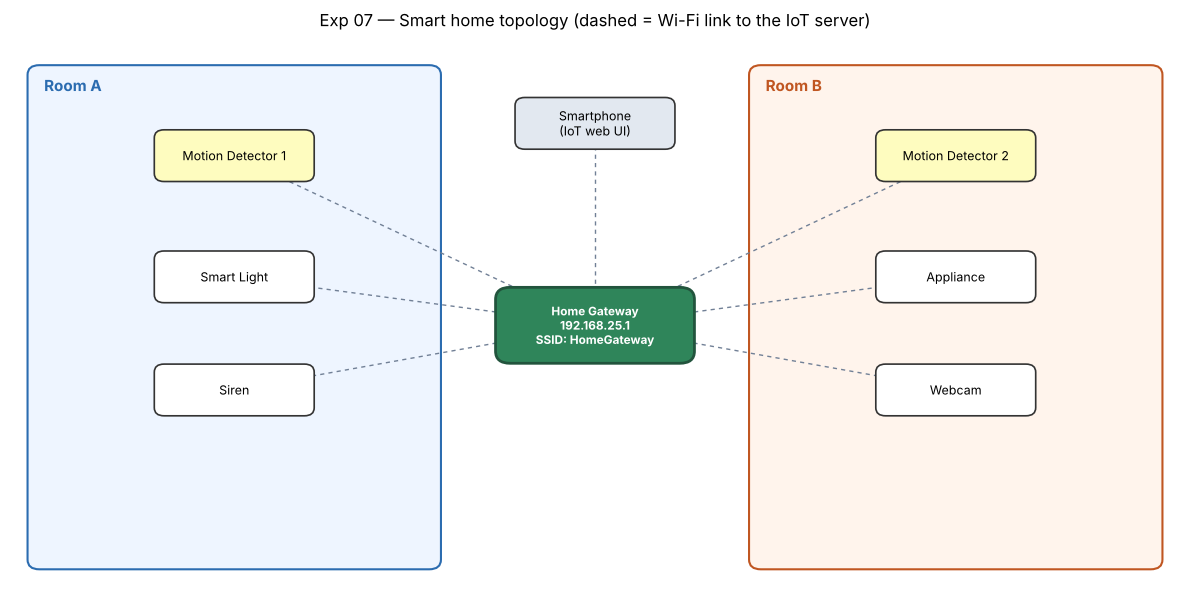

In [3]:
fig, ax = plt.subplots(figsize=(12, 6.2))
ax.set_xlim(0, 12); ax.set_ylim(0, 7); ax.axis("off")

def box(x, y, w, h, fc, ec, label=None, ls="-", lw=1.5, r=0.12):
    ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=f"round,pad=0.02,rounding_size={r}",
                                fc=fc, ec=ec, lw=lw, ls=ls))
    if label:
        ax.text(x + 0.15, y + h - 0.3, label, fontsize=11, fontweight="bold", color=ec)

def node(x, y, text, fc, ec="#333"):
    ax.add_patch(FancyBboxPatch((x - 0.8, y - 0.3), 1.6, 0.6, boxstyle="round,pad=0.02,rounding_size=0.1",
                                fc=fc, ec=ec, lw=1.2, zorder=3))
    ax.text(x, y, text, ha="center", va="center", fontsize=9, zorder=4)

GW = (6, 3.4)
box(0.2, 0.4, 4.2, 6.2, "#eef5ff", "#2b6cb0", "Room A")
box(7.6, 0.4, 4.2, 6.2, "#fff4ec", "#c05621", "Room B")
ax.add_patch(FancyBboxPatch((GW[0] - 1.0, GW[1] - 0.45), 2.0, 0.9, boxstyle="round,pad=0.02,rounding_size=0.15",
                            fc="#2f855a", ec="#22543d", lw=2, zorder=3))
ax.text(*GW, "Home Gateway\n192.168.25.1\nSSID: HomeGateway", ha="center", va="center", fontsize=8.5, color="white", fontweight="bold", zorder=4)

pos = {}
pos["Motion1"] = (2.3, 5.5); pos["Motion2"] = (9.7, 5.5)
for i, d in enumerate(ROOM_A):
    pos[d] = (2.3, 4.0 - i * 1.4)
for i, d in enumerate(ROOM_B):
    pos[d] = (9.7, 4.0 - i * 1.4)
for i, d in enumerate(HALL):
    pos[d] = (6, 1.2)
pos["Smartphone"] = (6, 5.9)

colors = {"Motion1": "#fefcbf", "Motion2": "#fefcbf"}
for k, (x, y) in pos.items():
    ax.plot([GW[0], x], [GW[1], y], ls=(0, (3, 3)), color="#718096", lw=1, zorder=1.5)
for k, (x, y) in pos.items():
    label = {"Motion1": "Motion Detector 1", "Motion2": "Motion Detector 2", "Smartphone": "Smartphone\n(IoT web UI)"}.get(k, NAMES.get(k, k))
    node(x, y, label, colors.get(k, "#e2e8f0" if k == "Smartphone" else "white"))
if HALL:
    ax.text(6, 0.65, "Hall / central", ha="center", fontsize=9, style="italic", color="#4a5568")
ax.set_title(f"Exp {EXP_NO:02d} — Smart home topology (dashed = Wi-Fi link to the IoT server)", fontsize=12)
plt.tight_layout(); plt.show()

In [4]:
rows = []
for md1 in (0, 1):
    for md2 in (0, 1):
        s = state(md1, md2)
        rows.append({"Motion Detector 1 (Room A)": "Motion" if md1 else "No motion",
                     "Motion Detector 2 (Room B)": "Motion" if md2 else "No motion",
                     **{NAMES[d]: s[d] for d in DEVICES}})
truth = pd.DataFrame(rows)

def colour(v):
    if v == "ON": return "background-color:#c6f6d5;color:#22543d;font-weight:bold"
    if v == "OFF": return "background-color:#fed7d7;color:#742a2a"
    return ""
display(Markdown("### Observation table — device states for every motion combination"))
display(truth.style.hide(axis="index").map(colour))

### Observation table — device states for every motion combination

Motion Detector 1 (Room A),Motion Detector 2 (Room B),Smart Light,Smart Fan,Siren,Appliance,Webcam
No motion,No motion,OFF,OFF,OFF,OFF,OFF
No motion,Motion,OFF,OFF,OFF,ON,ON
Motion,No motion,ON,OFF,ON,OFF,OFF
Motion,Motion,ON,OFF,ON,ON,ON


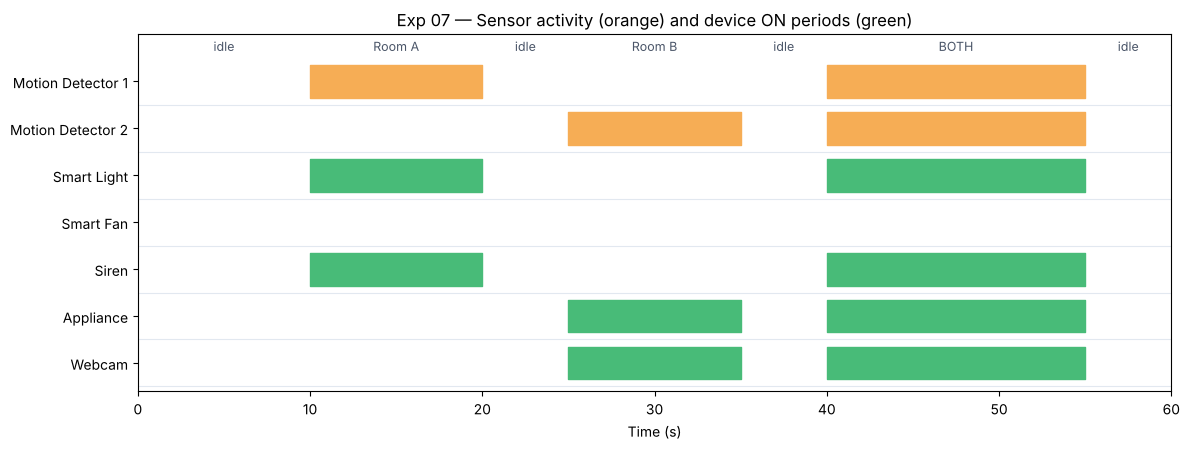

In [5]:
# Motion-event timeline (seconds) — what you see in Packet Tracer when you trigger the sensors
events = [(0, 0, 0), (10, 1, 0), (20, 0, 0), (25, 0, 1), (35, 0, 0), (40, 1, 1), (55, 0, 0), (60, 0, 0)]
times, trace = [], []
devs = {d: "OFF" for d in DEVICES}
for (t0, m1, m2), (t1, _, _) in zip(events[:-1], events[1:]):
    devs = state(m1, m2, devs)
    trace.append((t0, t1, m1, m2, dict(devs)))

labels = ["Motion Detector 1", "Motion Detector 2"] + [NAMES[d] for d in DEVICES]
fig, ax = plt.subplots(figsize=(12, 4.6))
for row, lab in enumerate(labels):
    y = len(labels) - 1 - row
    for t0, t1, m1, m2, dv in trace:
        if row == 0: on = m1
        elif row == 1: on = m2
        else: on = dv[DEVICES[row - 2]] == "ON"
        if on:
            ax.broken_barh([(t0, t1 - t0)], (y - 0.35, 0.7), color="#f6ad55" if row < 2 else "#48bb78")
    ax.axhline(y - 0.5, color="#e2e8f0", lw=0.8)
ax.set_yticks(range(len(labels))); ax.set_yticklabels(labels[::-1])
for t0, t1, m1, m2, _ in trace:
    txt = {(0,0): "idle", (1,0): "Room A", (0,1): "Room B", (1,1): "BOTH"}[(m1, m2)]
    ax.text((t0 + t1) / 2, len(labels) - 0.35, txt, ha="center", fontsize=9, color="#4a5568")
ax.set_xlim(0, 60); ax.set_ylim(-0.6, len(labels)); ax.set_xlabel("Time (s)")
ax.set_title(f"Exp {EXP_NO:02d} — Sensor activity (orange) and device ON periods (green)")
plt.tight_layout(); plt.show()

In [6]:
results = []
def check(text, ok):
    results.append((text, ok))
    print(("PASS  " if ok else "FAIL  ") + text)

check("Statement 1: MD1 motion -> Smart Light ON", all(state(1, m2)["Light"] == "ON" for m2 in (0, 1)))
check("Statement 1: MD1 motion -> Siren ON", all(state(1, m2)["Siren"] == "ON" for m2 in (0, 1)))
check("Statement 2: MD2 motion -> Appliance ON", all(state(m1, 1)["Appliance"] == "ON" for m1 in (0, 1)))
check("Statement 2: MD2 motion -> Webcam ON", all(state(m1, 1)["Webcam"] == "ON" for m1 in (0, 1)))
check("Statement 3: MD1 no motion -> Smart Light OFF", all(state(0, m2)["Light"] == "OFF" for m2 in (0, 1)))
print()
print("All requirements satisfied" if all(ok for _, ok in results) else "Some requirement FAILED")

PASS  Statement 1: MD1 motion -> Smart Light ON
PASS  Statement 1: MD1 motion -> Siren ON
PASS  Statement 2: MD2 motion -> Appliance ON
PASS  Statement 2: MD2 motion -> Webcam ON
PASS  Statement 3: MD1 no motion -> Smart Light OFF

All requirements satisfied


## Result
The smart home was built around the Home Gateway, all IoT devices were registered on its IoT server over Wi-Fi, and the conditions were configured from the IoT web interface. Motion in Room A switched ON the Smart Light and Siren; motion in Room B switched ON the Appliance and Webcam. When Room A had no motion the Smart Light switched OFF, confirming the NOT (On is false) condition. All requirement checks above report **PASS**.

## Conclusion
A rule-based IoT automation system was successfully designed and simulated. The Home Gateway acts as a central IoT server: sensors publish their state, and IF–THEN conditions translate that state into actuator commands. Single-sensor rules give room-level automation, while testing a sensor for *On is false* implements a logical NOT (no-motion) condition. Pairing every ON rule with a reset rule keeps device states consistent with the actual occupancy, which is essential for both energy saving and security.